# Question accuracy for several models

Which of several questions (prompts) gets the most images right for each model, and do the models agree on which question works best?

**How to use:** fill in the two paths in the next cell and run all cells. Tables and plots are saved in `comparison_results/` next to the result file.

In [1]:
# ============ SETTINGS: the only cell you need to change ============
RESULTS_FILES = [                                  # csv file(s) with the model answers
    "../emotions_output/openai__gpt-4o-mini.csv",
    "../emotions_output/google__gemini-2.5-flash.csv",
    "../emotions_output/qwen__qwen2.5-vl-72b-instruct.csv",
    "../emotions_output/meta-llama__llama-4-maverick.csv",
]
IMAGE_DIR = "../emotions_output/emo_data"          # folder with the images

**Other datasets** – the dataset (emotions, politicians or symbols) is detected from the image names in the result file, so only the paths change, e.g.:
```python
RESULTS_FILES = "../politicians_output/Delia/comparison_vqa_politicians_OpenRouter.csv"
IMAGE_DIR = "../politicians_output/politicians_nonpoliticians_dataset_final/politicians_nonpoliticians_dataset"

RESULTS_FILES = "../symbols_output/results/merged_coded_symbols.csv"
IMAGE_DIR = "../symbols_output/images/symbol_images"
```
The result file can be an ammico output (`filename` + `vqa`), a table with one answer column per model, or the coded table of the symbols package. Questions, ground truth and expected answers are defined in `DATASETS` in `vqa_eval_utils.py`.

## 1. Data and questions

In [2]:
import vqa_eval_utils as U

run = U.load(RESULTS_FILES, IMAGE_DIR, "question_accuracy_models")
U.show_questions(run)

dataset: emotions  |  models: gpt-4o-mini, gemini-2.5-flash, qwen2.5-vl-72b-instruct, llama-4-maverick
images: 300 in the results, 300 with ground truth, 0 found in ../emotions_output/emo_data
images answered completely by all models (used for the comparison): 262
output folder: ../emotions_output/comparison_results/question_accuracy_models


,type,style,question,expected answer (label -> answer)
qid,,,,
Q1,polarity,<pandas.io.formats.style.Styler object at 0x787faa56be60>,Does the picture show any positive or negative emotional content?,"positive -> positive, negative -> negative, neutral -> none"
Q2,polarity,<pandas.io.formats.style.Styler object at 0x787faa56be60>,"Does the picture show any positive or negative emotional content? Answer as applicable: positive, negative, both, none, or DK. Do not guess.","positive -> positive, negative -> negative, neutral -> none"
Q3,negative,<pandas.io.formats.style.Styler object at 0x787faa56be60>,Does the picture show any negative emotional content?,"positive -> no, negative -> yes, neutral -> no"
Q4,negative,<pandas.io.formats.style.Styler object at 0x787faa56be60>,"Does the picture show any negative emotional content? Answer as applicable: yes, no or DK. Do not guess.","positive -> no, negative -> yes, neutral -> no"
Q5,negative,<pandas.io.formats.style.Styler object at 0x787faa56be60>,"Does the picture show any negative emotional content, either because of the facial or body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer as...","positive -> no, negative -> yes, neutral -> no"
Q6,positive,<pandas.io.formats.style.Styler object at 0x787faa56be60>,Does the picture show any positive emotional content?,"positive -> yes, negative -> no, neutral -> no"
Q7,positive,<pandas.io.formats.style.Styler object at 0x787faa56be60>,"Does the picture show any positive emotional content? Answer as applicable: yes, no or DK. Do not guess.","positive -> yes, negative -> no, neutral -> no"
Q8,positive,<pandas.io.formats.style.Styler object at 0x787faa56be60>,"Does the picture show any positive emotional content, either because of the facial and body displays of the individuals, or because of what it depicts, or because of the text it contains? Answer a...","positive -> yes, negative -> no, neutral -> no"


## 2. From free text to answers
Each answer is mapped to a category (yes / no / dk, …) by the rules of its question type. `exact`, `first` and `package_code` are safe; the keyword rules (`kw_*`) are heuristics, so read the sample of raw answers below against their `normalised` value. Only images answered by all models are used, so all models are compared on the same images.

In [3]:
U.show_normalisation(run)

answer_is  exact  first  kw_affirm  kw_both  kw_dk  kw_negated  kw_neutral  kw_none  kw_none_however  kw_opposite  kw_polarity  unparsed
qid model                                                                                                                                                            
Q1  gemini-2.5-flash                 0     89      5          0        0      0           0           3       58                3            0          104         0
    gpt-4o-mini                      0      0      0          0        2      6           0          32       20                0            0          202         0
    llama-4-maverick                 1      0      0          0        2      8           0           8       43                0            0          200         0
    qwen2.5-vl-72b-instruct          0     81      0          0        0      0           0           1       62                1            0          117         0
Q2  gemini-2.5-flash                 0    262      0          0        0      0           0           0        0                0            0            0         0
    gpt-4o-mini                      0    261      0          0        0      0           0           0        0                0            0            1         0
    llama-4-maverick                41    189      0          0        2      0           0           1        1                0            0           28         0
    qwen2.5-vl-72b-instruct          0    262      0          0        0      0           0           0        0                0            0            0         0
Q3  gemini-2.5-flash                 0      6    256          0        0      0           0           0        0                0            0            0         0
    gpt-4o-mini                      0      0    202         11        0      9          37           0        0                0            2            0         1
    llama-4-maverick                 3      7     89         39        0      0         122           0        0                0            2            0         0
    qwen2.5-vl-72b-instruct          0    240     22          0        0      0           0           0        0                0            0            0         0
Q4  gemini-2.5-flash                 0    262      0          0        0      0           0           0        0                0            0            0         0
    gpt-4o-mini                      0    262      0          0        0      0           0           0        0                0            0            0         0
    llama-4-maverick                 0    262      0          0        0      0           0           0        0                0            0            0         0
    qwen2.5-vl-72b-instruct          0    262      0          0        0      0           0           0        0                0            0            0         0
Q5  gemini-2.5-flash                 0    262      0          0        0      0           0           0        0                0            0            0         0
    gpt-4o-mini                      0    262      0          0        0      0           0           0        0                0            0            0         0
    llama-4-maverick                 1    259      0          0        0      0           2           0        0                0            0            0         0
    qwen2.5-vl-72b-instruct          0    262      0          0        0      0           0           0        0                0            0            0         0
Q6  gemini-2.5-flash                 0     23    238          0        0      1           0           0        0                0            0            0         0
    gpt-4o-mini                      0      0    155          5        0     16          76           0        0                0           10            0         0
    llama-4-maverick                 7      9

1312 distinct keyword-mapped or unparsed answers (all in ../emotions_output/comparison_results/question_accuracy_models/mapping_review.csv); sample:


,model,qid,rule,normalised,raw
431,gpt-4o-mini,Q3,unparsed,unparsed,"The image appears to convey a serious or intense emotional tone, given the context of the text and the subject's expression."
1141,llama-4-maverick,Q6,kw_opposite,no,"The image depicts a man and woman in close proximity, with the woman's hand on the man's chest. The woman's facial expression appears to be one of concern or worry, while the man's face is partial..."
534,llama-4-maverick,Q1,answer_is,none,"The image depicts a man with a neutral expression, wearing a dark blue suit jacket and white shirt. The man's facial expression is serious, but it does not convey any strong positive or negative e..."
460,gpt-4o-mini,Q6,kw_negated,no,The image does not convey clear positive emotional content; it appears more neutral or serious.
1152,qwen2.5-vl-72b-instruct,Q1,kw_none,none,"The picture does not show any clear positive or negative emotional content. The man's expression appears neutral, and there are no strong emotional indicators in the text or imagery."
...,...,...,...,...,...
535,llama-4-maverick,Q1,kw_both,both,"The image shows a man and a young woman posing for a photo, with the man smiling and the woman smiling slightly. The atmosphere appears to be positive, as the individuals in the foreground are smi..."
59,gemini-2.5-flash,Q1,kw_none_however,negative,"The picture itself does not show any strong positive or negative emotional content. The woman in the image has a neutral to slightly smiling expression. However, the text overlaid on the image, ""U..."
968,llama-4-maverick,Q3,kw_opposite,no,"The image depicts a man and woman casting their votes, with both individuals displaying smiles. The overall atmosphere of the scene is positive, as they appear to be engaged in the democratic proc..."
139,gpt-4o-mini,Q1,kw_both,both,"The picture conveys a mix of emotions; the rainbow suggests positivity, while the mention of record rainfall may imply negativity or concern."


> **Result:** 262 images have results and a ground-truth label (label: number of images – negative: 93, positive: 88, neutral: 66, unclear: 15). 1468 of 8384 answers needed keyword rules and 1 remains unparsed. 38 images are dropped because a model has no answer for them.

## 3. Accuracy per question
**Accuracy** = share of images whose (normalised) answer matches the expected answer from the ground truth. DK, unclear and unparsed answers count as **wrong**; images without an expected answer (e.g. label `unclear`) are not scored.
The **majority baseline** is the accuracy of always giving the most frequent expected answer – a question is only useful if it beats it clearly. Error bars are 95% Wilson confidence intervals.

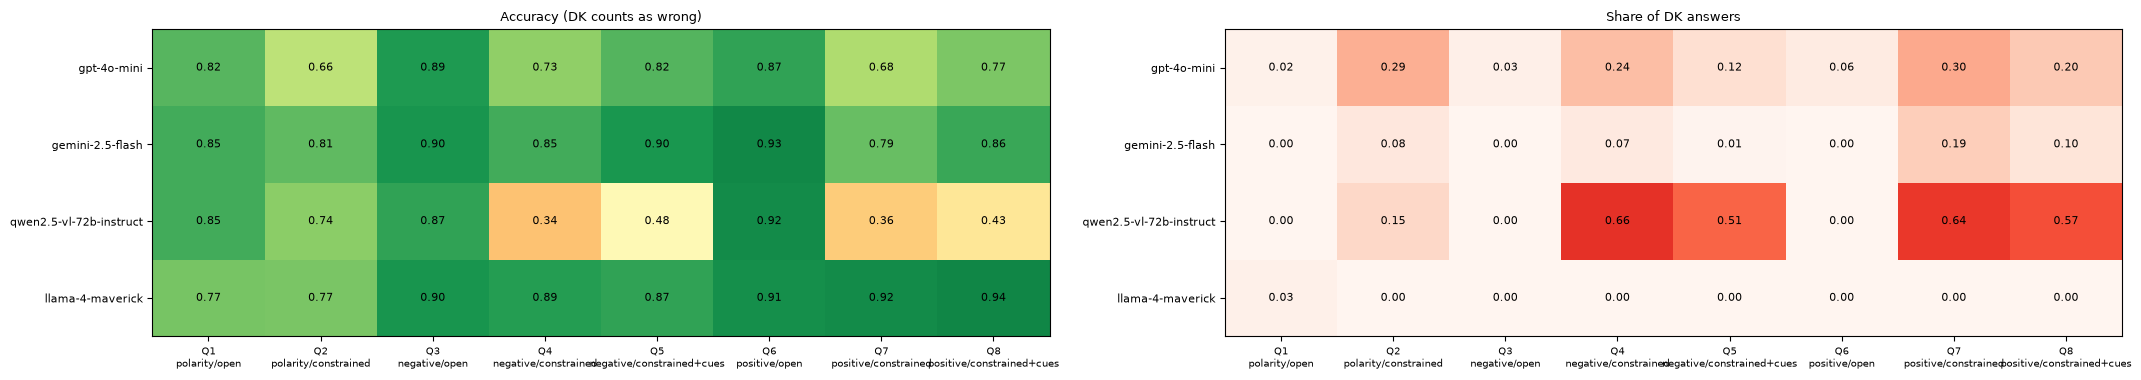

qid,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8
majority_baseline,0.377,0.377,0.623,0.623,0.623,0.644,0.644,0.644


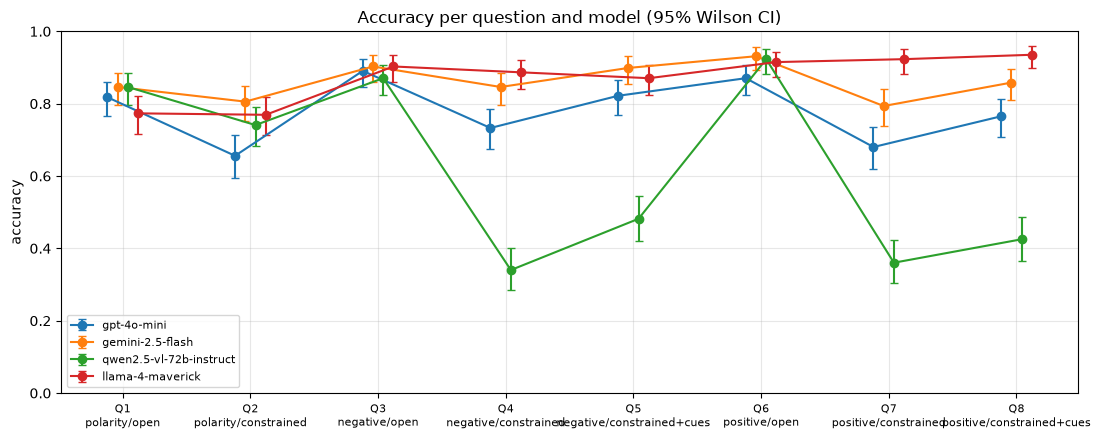

> **Result:** Accuracy range per model: gpt-4o-mini 0.66–0.89 (best Q3), gemini-2.5-flash 0.79–0.93 (best Q6), qwen2.5-vl-72b-instruct 0.34–0.92 (best Q6) and llama-4-maverick 0.77–0.94 (best Q8). The best combination is llama-4-maverick with Q8 (0.94). High DK shares lower the accuracy for qwen2.5-vl-72b-instruct Q4 (66%), qwen2.5-vl-72b-instruct Q7 (64%), qwen2.5-vl-72b-instruct Q8 (57%), qwen2.5-vl-72b-instruct Q5 (51%) and gpt-4o-mini Q7 (30%).  The models agree most on Q3 (spread 0.03) and differ most on Q7 (spread 0.56 between the best and the worst model).

In [4]:
acc = U.show_accuracy(run)

## 4. Accuracy per image group
The same accuracy for each image group and model: a low value shows which kind of image makes a question fail.

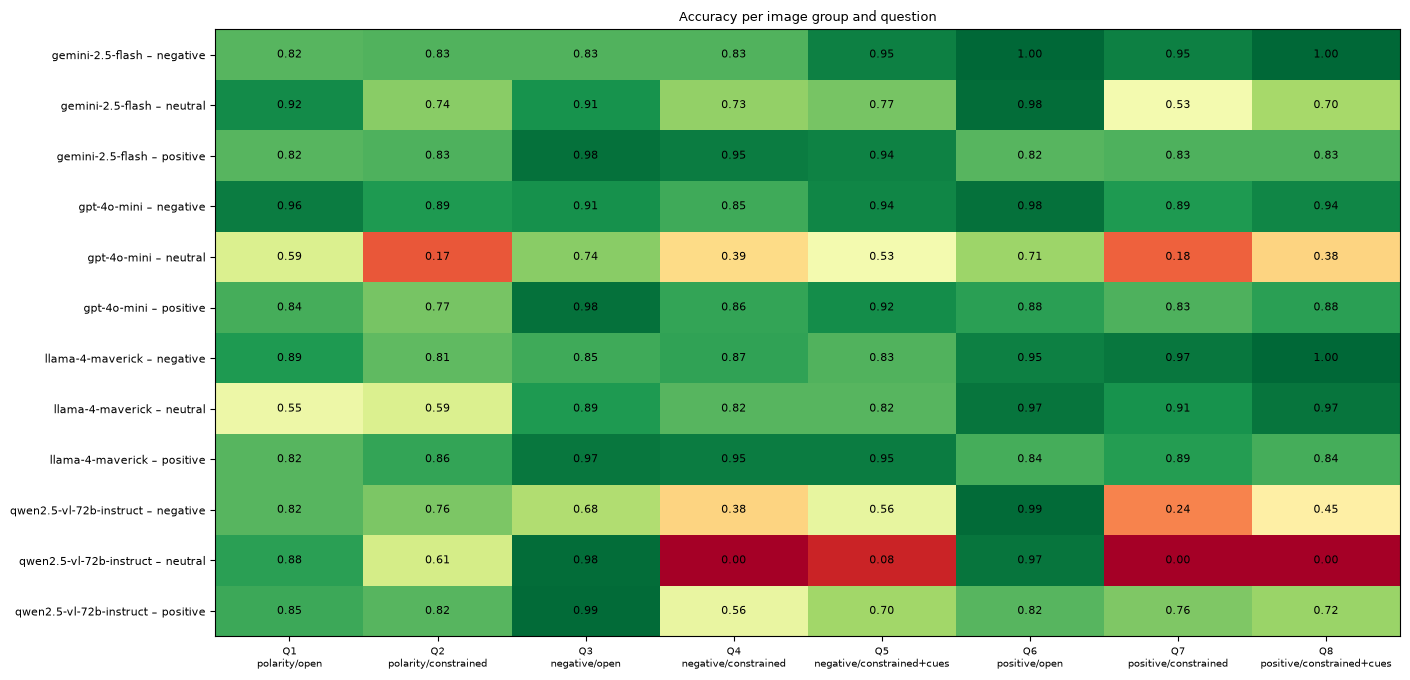

> **Result:** Weakest group and question per model – gemini-2.5-flash: neutral with Q7 (0.53), gpt-4o-mini: neutral with Q2 (0.17), llama-4-maverick: neutral with Q1 (0.55) and qwen2.5-vl-72b-instruct: neutral with Q8 (0.00).

In [5]:
U.show_groups(run, acc)

## 5. Which differences between questions are significant?
Each pair of questions is compared on the same images with an exact McNemar test (Holm-corrected). Blue = the row question is more accurate, red = less accurate, * = significant.

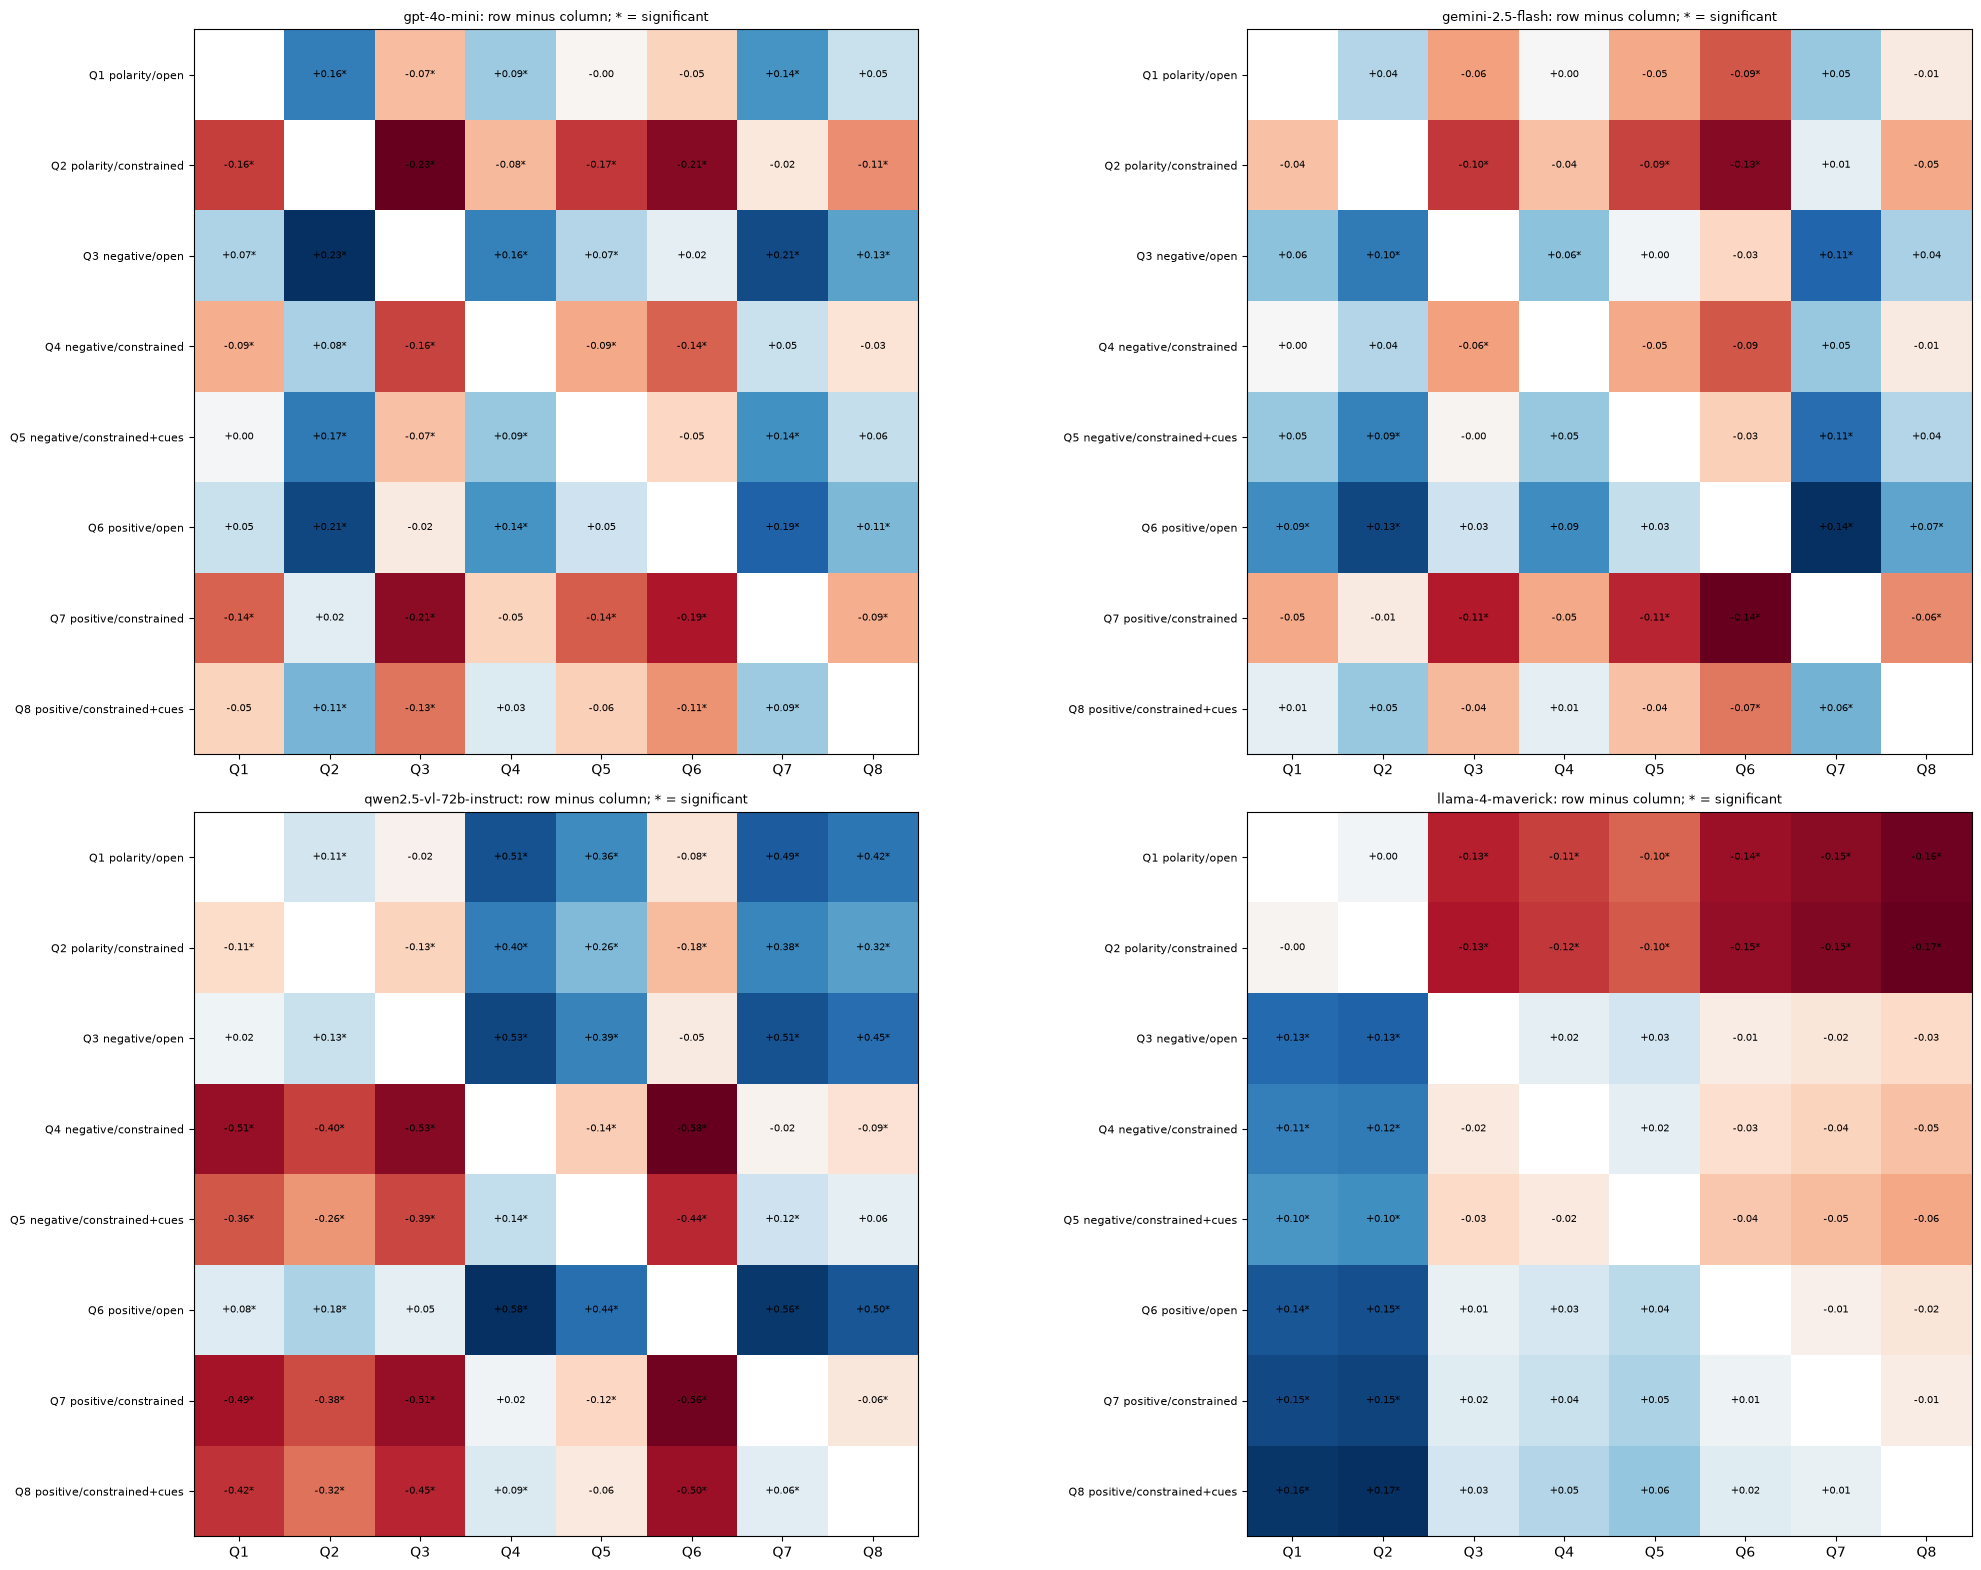

> **Result:** Significant question differences (of 28 pairs): gpt-4o-mini 19, gemini-2.5-flash 10, qwen2.5-vl-72b-instruct 24 and llama-4-maverick 12. 

In [6]:
tests = U.show_pairs(run)

## 6. Summary: which question to use?
The most accurate question per model and the questions that are not significantly worse. A question that is never significantly worse is a safe choice across models.

In [7]:
U.show_best(run, acc, tests)

,model,best_question,best_accuracy,not_significantly_worse,worst_question,worst_accuracy,mean_accuracy
0,gpt-4o-mini,Q3,0.891,"Q3, Q6",Q2,0.656,0.779
1,gemini-2.5-flash,Q6,0.931,"Q3, Q4, Q5, Q6",Q7,0.794,0.860
2,qwen2.5-vl-72b-instruct,Q6,0.923,"Q3, Q6",Q4,0.340,0.623
3,llama-4-maverick,Q8,0.935,"Q3, Q4, Q5, Q6, Q7, Q8",Q2,0.769,0.872


> **Result:** Best question per model – gpt-4o-mini: Q3 (0.89), gemini-2.5-flash: Q6 (0.93), qwen2.5-vl-72b-instruct: Q6 (0.92) and llama-4-maverick: Q8 (0.94). Q3 and Q6 are the best or not significantly worse than the best for every model, i.e. a safe choice across models.

## 7. Difficult images
How many answers go wrong per image, and the hardest images of each group. Errors on every question point to a hard image or a questionable label; errors on some questions point to the wording.

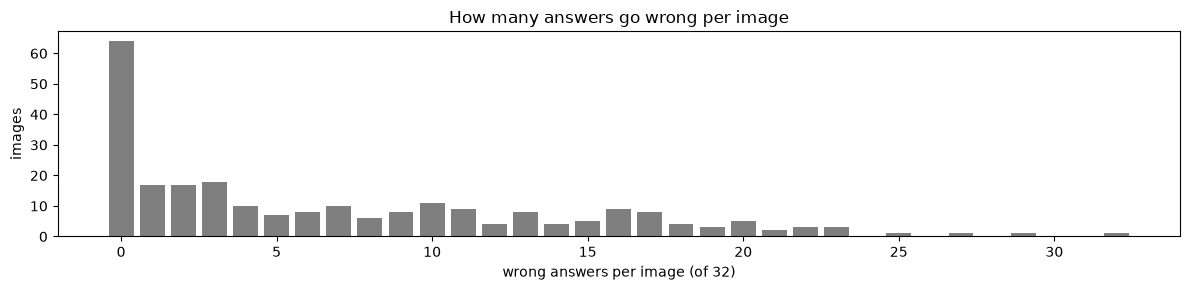

images  mean_share_wrong  hard_images (≥50% wrong)
group    subfolder                                                                    
positive neutral_vis_positive_text      10              0.72                         9
neutral  folder1                        39              0.41                        13
         folder2                        27              0.32                         4
negative neutral_vis_negative_text      28              0.28                         7
         nonviolent_2                    7              0.25                         2
         nonviolent_1                   19              0.22                         3
positive folder2                        12              0.22                         1
negative violent_2                       7              0.12                         0
positive folder1                        66              0.05                         2
negative violent_1                      32              0.04                         0

> **Result:** 64 of 247 images are answered correctly in all 32 answers, and 41 are wrong in half or more (17 neutral, 12 positive, 12 negative). The hardest group is neutral (37% wrong answers on average), the easiest positive (15%).

**Hardest images per group** – left: the image; right: expected answer (first row) and normalised answers, green = correct, red = wrong. Below: the raw wrong answers.

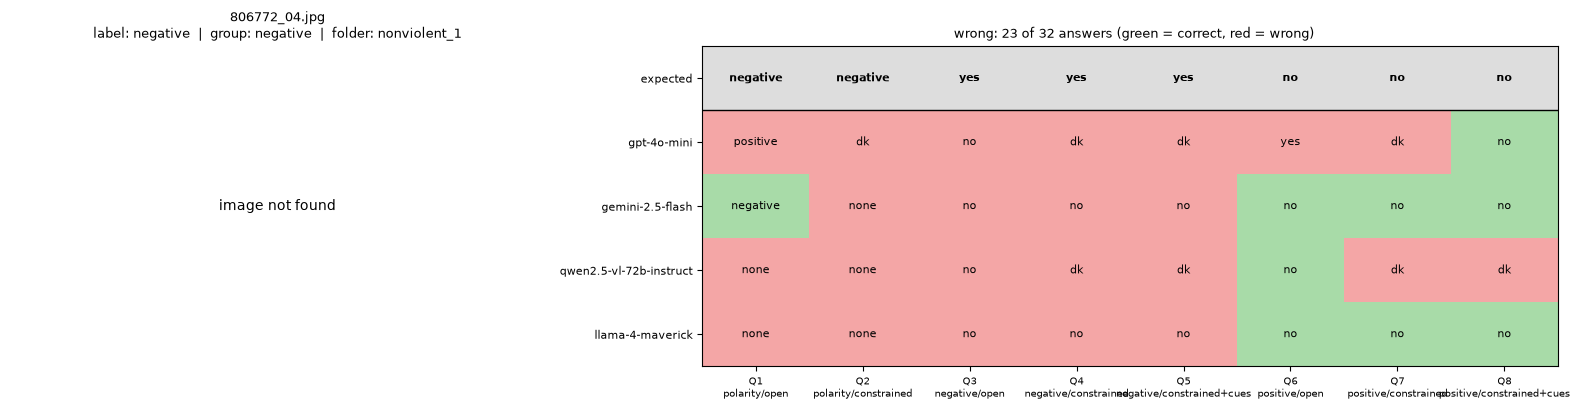

,model,qid,truth,pred,raw
0,gpt-4o-mini,Q1,negative,positive,"The picture conveys a sense of calm or introspection, which can be interpreted as positive emotional content."
1,qwen2.5-vl-72b-instruct,Q1,negative,none,"The picture does not clearly show any strong positive or negative emotional content. The person's face is partially obscured by the hood, making it difficult to"
2,llama-4-maverick,Q1,negative,none,The image does not display any emotional content.
3,gpt-4o-mini,Q2,negative,dk,DK
4,gemini-2.5-flash,Q2,negative,none,None.
5,qwen2.5-vl-72b-instruct,Q2,negative,none,none
6,llama-4-maverick,Q2,negative,none,none.
7,gpt-4o-mini,Q3,yes,no,"The picture appears to convey a sense of contemplation or introspection, but it does not explicitly show negative emotional content."
8,gemini-2.5-flash,Q3,yes,no,"No, the picture does not show any negative emotional content. The person's eyes are closed, suggesting a moment of calm or contemplation rather than distress."
9,qwen2.5-vl-72b-instruct,Q3,yes,no,No


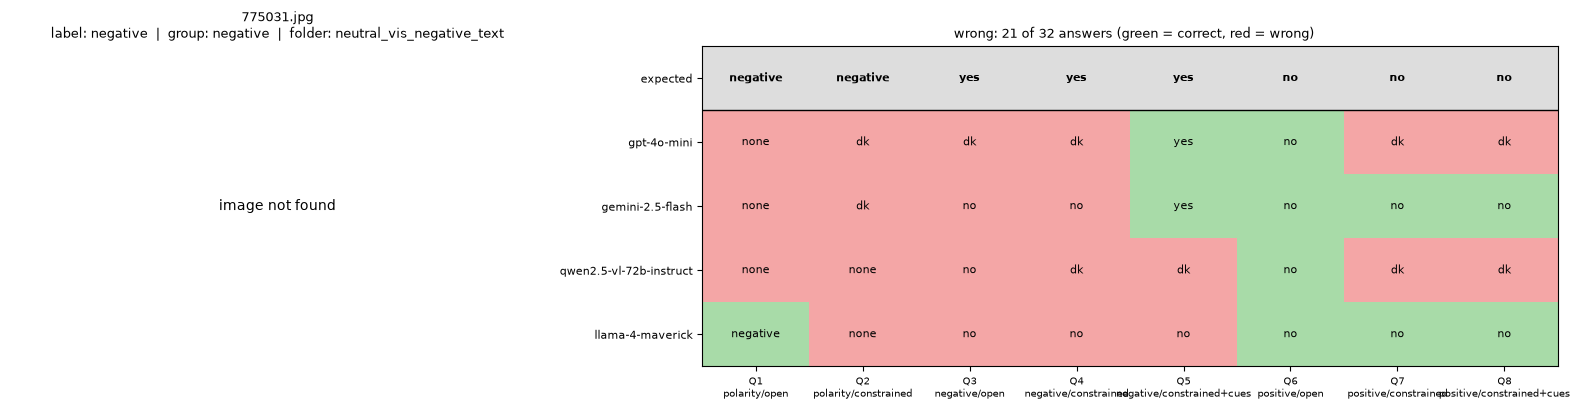

,model,qid,truth,pred,raw
0,gpt-4o-mini,Q1,negative,none,"The picture conveys a neutral emotional content, as the subject appears calm and contemplative."
1,gemini-2.5-flash,Q1,negative,none,The man in the picture appears to have a neutral or slightly contemplative expression. There is no strong indication of positive or negative emotional content.
2,qwen2.5-vl-72b-instruct,Q1,negative,none,"The picture shows neutral emotional content. The person appears to be in a calm and composed state, with no strong positive or negative emotions evident."
3,gpt-4o-mini,Q2,negative,dk,DK
4,gemini-2.5-flash,Q2,negative,dk,DK
5,qwen2.5-vl-72b-instruct,Q2,negative,none,none
6,llama-4-maverick,Q2,negative,none,"The image shows a man with a neutral expression, and the text at the bottom appears to be a quote in Hungarian. The overall tone of the image is not clearly pos"
7,gpt-4o-mini,Q3,yes,dk,"The image appears to show a person with a serious expression, which could suggest concern or contemplation. However, without more context, it's difficult to def"
8,gemini-2.5-flash,Q3,yes,no,"No, the picture does not show any negative emotional content. The man in the image has a neutral to slightly contemplative expression."
9,qwen2.5-vl-72b-instruct,Q3,yes,no,No


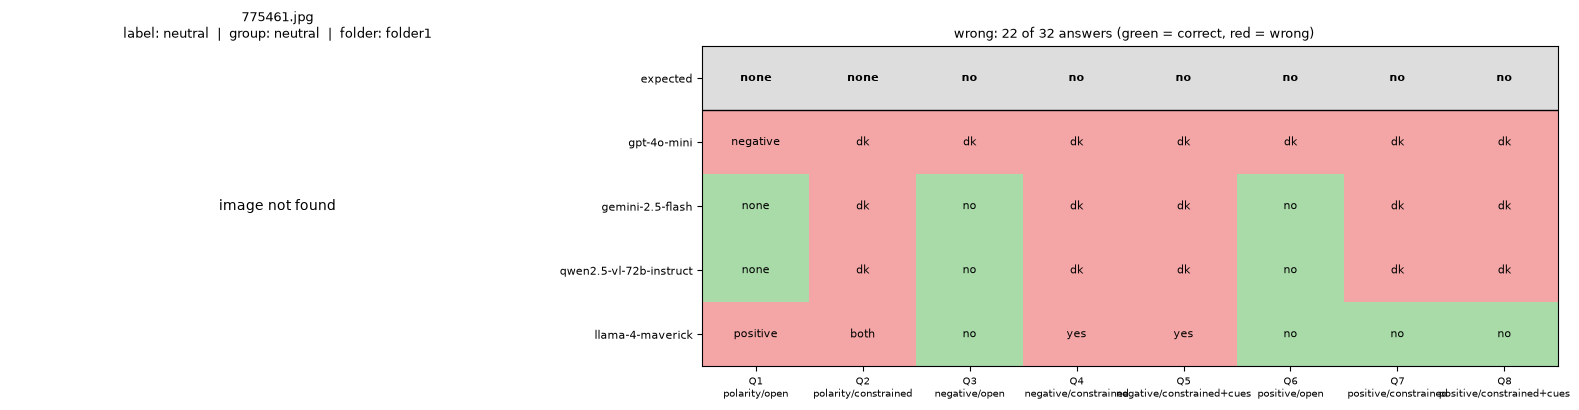

,model,qid,truth,pred,raw
0,gpt-4o-mini,Q1,none,negative,"The picture likely conveys a serious or passionate emotional tone, suggesting a potentially negative context, as the individual appears to be speaking at a publ"
1,llama-4-maverick,Q1,none,positive,"The image depicts a man speaking into a microphone, surrounded by a crowd of people. The man's facial expression and body language convey a sense of seriousness"
2,gpt-4o-mini,Q2,none,dk,DK
3,gemini-2.5-flash,Q2,none,dk,DK
4,qwen2.5-vl-72b-instruct,Q2,none,dk,DK
5,llama-4-maverick,Q2,none,both,both.
6,gpt-4o-mini,Q3,no,dk,"The image depicts a person speaking in front of a crowd, which may suggest a serious or passionate context, but without additional context, it's unclear if ther"
7,gpt-4o-mini,Q4,no,dk,DK
8,gemini-2.5-flash,Q4,no,dk,DK
9,qwen2.5-vl-72b-instruct,Q4,no,dk,DK


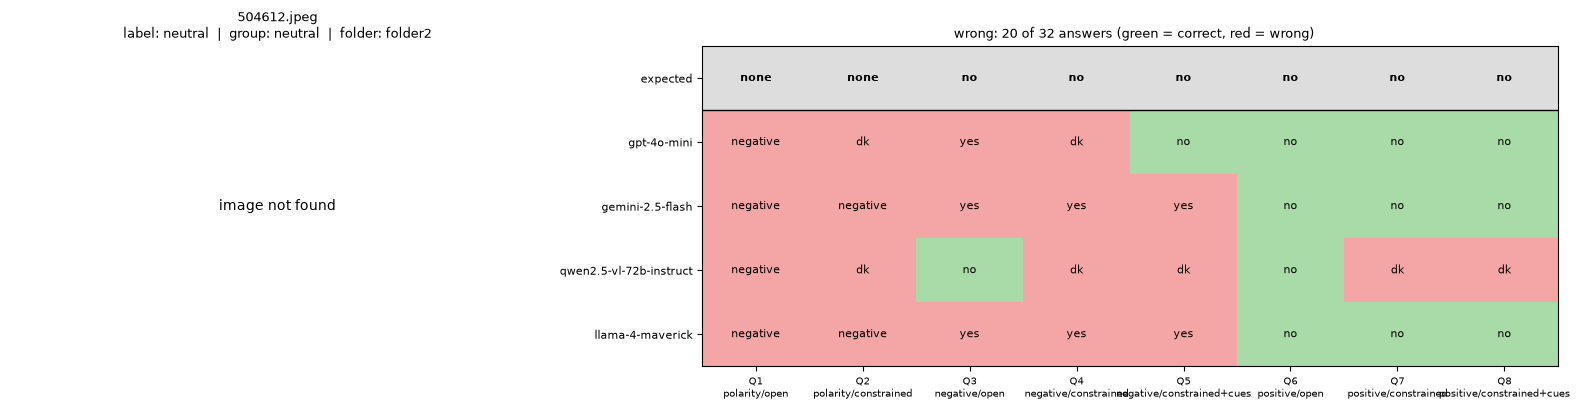

,model,qid,truth,pred,raw
0,gpt-4o-mini,Q1,none,negative,"The picture suggests a negative emotional content, as the person appears to be looking at an empty wallet, which may indicate concern or disappointment."
1,gemini-2.5-flash,Q1,none,negative,Negative.
2,qwen2.5-vl-72b-instruct,Q1,none,negative,"The picture shows negative emotional content. The person appears to be holding an empty wallet, which typically symbolizes financial stress or lack of money. Th"
3,llama-4-maverick,Q1,none,negative,"The image depicts a person holding an empty wallet, which is often associated with financial difficulties or stress. The presence of bills on the table may sugg"
4,gpt-4o-mini,Q2,none,dk,DK
5,gemini-2.5-flash,Q2,none,negative,Negative
6,qwen2.5-vl-72b-instruct,Q2,none,dk,DK
7,llama-4-maverick,Q2,none,negative,negative.
8,gpt-4o-mini,Q3,no,yes,"Yes, the picture may suggest negative emotional content, as the person appears to be looking at an empty wallet, which can imply feelings of concern or disappoi"
9,gemini-2.5-flash,Q3,no,yes,"Yes, the picture shows negative emotional content. The person is holding an empty wallet, which typically signifies financial distress, worry, or disappointment"


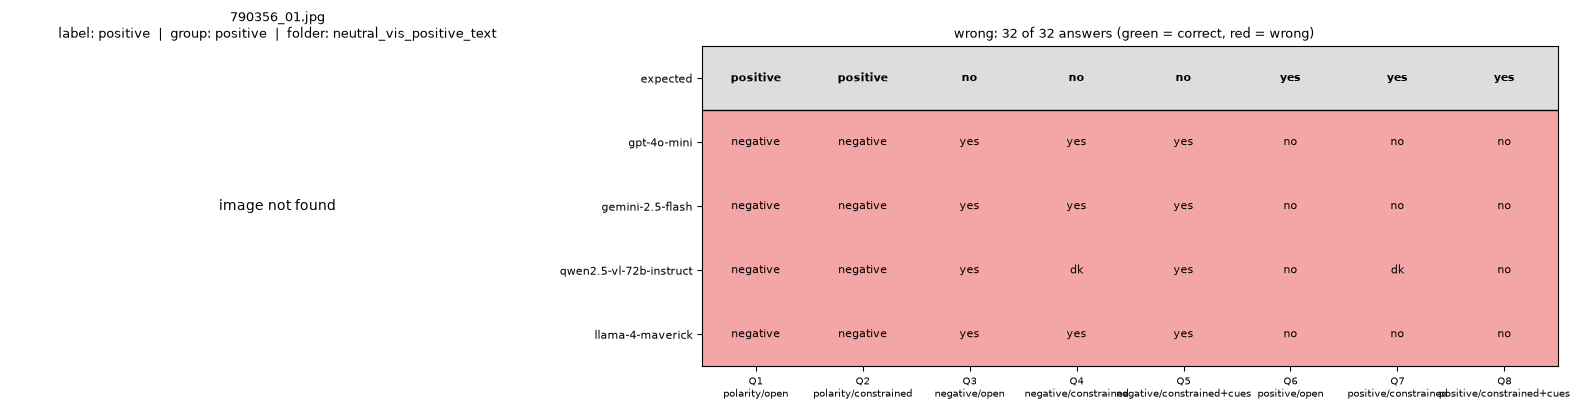

,model,qid,truth,pred,raw
0,gpt-4o-mini,Q1,positive,negative,"The picture conveys a negative emotional content, as it features a serious expression and discusses a distressing topic related to substance use."
1,gemini-2.5-flash,Q1,positive,negative,The picture shows **negative** emotional content.
2,qwen2.5-vl-72b-instruct,Q1,positive,negative,"The picture shows negative emotional content. The quote suggests feelings of confusion and distress, indicating a negative experience related to being drugged w"
3,llama-4-maverick,Q1,positive,negative,"The image depicts a young girl with a somber expression, accompanied by a quote in Hungarian that translates to ""I didn't turn my head because I was crying beca"
4,gpt-4o-mini,Q2,positive,negative,Negative
5,gemini-2.5-flash,Q2,positive,negative,Negative.
6,qwen2.5-vl-72b-instruct,Q2,positive,negative,negative
7,llama-4-maverick,Q2,positive,negative,"The image depicts a young girl with a somber expression, accompanied by a quote in Hungarian that translates to ""I didn't turn my head because I was crying beca"
8,gpt-4o-mini,Q3,no,yes,"Yes, the quote suggests a negative emotional context related to feelings of distress or sadness."
9,gemini-2.5-flash,Q3,no,yes,"Yes, the picture shows negative emotional content. The woman's expression appears serious and somewhat distressed, and the text discusses a distressing experien"


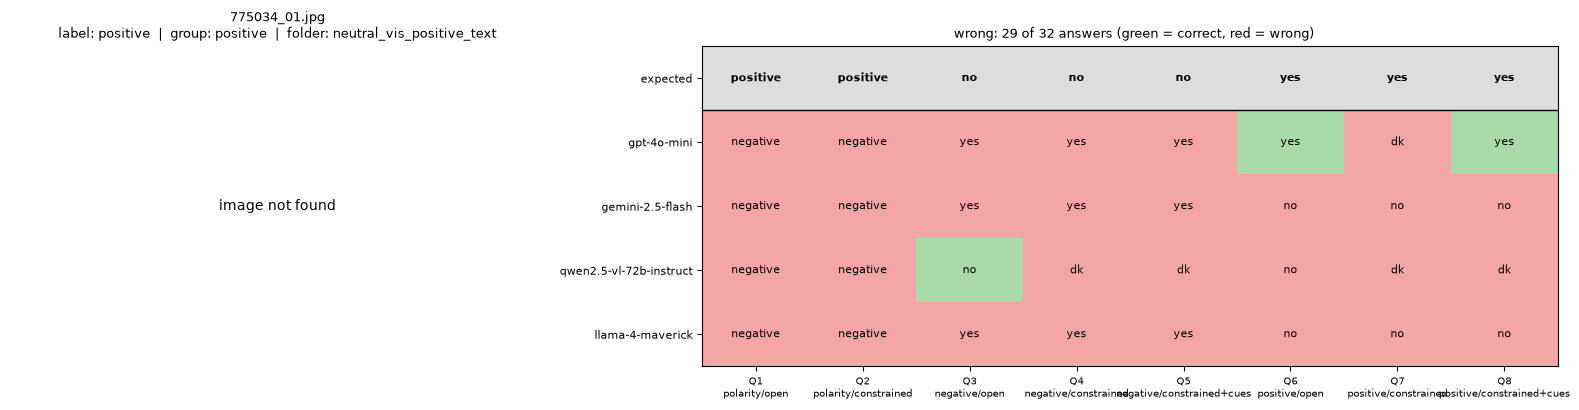

,model,qid,truth,pred,raw
0,gpt-4o-mini,Q1,positive,negative,"The picture conveys a negative emotional content, as it expresses a strong political message against Russian presence and emphasizes a stance of resistance."
1,gemini-2.5-flash,Q1,positive,negative,"The picture shows **negative** emotional content. The text ""RUSSIANS GO HOME"" and ""RUSZIK HAZA! DEMOCRACY WILL NOT RETREAT."" expresses strong opposition and def"
2,qwen2.5-vl-72b-instruct,Q1,positive,negative,"The picture shows negative emotional content, as it conveys a message of confrontation and resistance against Russian influence, using strong language like ""Rus"
3,llama-4-maverick,Q1,positive,negative,"The image conveys a negative emotional tone, as indicated by the text ""Russians go home"" and ""Democracy will not retreat."" The overall atmosphere is one of oppo"
4,gpt-4o-mini,Q2,positive,negative,Negative
5,gemini-2.5-flash,Q2,positive,negative,Negative.
6,qwen2.5-vl-72b-instruct,Q2,positive,negative,negative
7,llama-4-maverick,Q2,positive,negative,"The image conveys a negative emotional tone, as indicated by the text ""Russians go home"" and the overall context of the quote, which appears to be related to a"
8,gpt-4o-mini,Q3,no,yes,"Yes, the picture conveys a message of resistance and opposition, which can be interpreted as negative emotional content directed towards a specific group."
9,gemini-2.5-flash,Q3,no,yes,"Yes, the picture shows negative emotional content. The text ""RUSSIANS GO HOME"" and ""RUSZIK HAZA!"" (which translates to ""Russians home!"" or ""Russian go home!"" in"


> **Result:** `806772_04.jpg` (negative): 23 of 32 answers wrong by gpt-4o-mini, qwen2.5-vl-72b-instruct, llama-4-maverick and gemini-2.5-flash; most often "no" instead of "yes" (8x).<br>`775031.jpg` (negative): 21 of 32 answers wrong by qwen2.5-vl-72b-instruct, gpt-4o-mini, gemini-2.5-flash and llama-4-maverick; most often "no" instead of "yes" (6x).<br>`775461.jpg` (neutral): 22 of 32 answers wrong by gpt-4o-mini, gemini-2.5-flash, qwen2.5-vl-72b-instruct and llama-4-maverick; most often "dk" instead of "no" (14x).<br>`504612.jpeg` (neutral): 20 of 32 answers wrong by qwen2.5-vl-72b-instruct, gemini-2.5-flash, llama-4-maverick and gpt-4o-mini; most often "yes" instead of "no" (7x).<br>`790356_01.jpg` (positive): 32 of 32 answers wrong by gpt-4o-mini, gemini-2.5-flash, qwen2.5-vl-72b-instruct and llama-4-maverick; most often "no" instead of "yes" (11x).<br>`775034_01.jpg` (positive): 29 of 32 answers wrong by gemini-2.5-flash, llama-4-maverick, qwen2.5-vl-72b-instruct and gpt-4o-mini; most often "yes" instead of "no" (9x).<br>Look at the images: errors on every question point to a hard image or a questionable label, errors on some questions to the wording.

In [8]:
U.show_difficult_images(run)